# Homework 2, Part 2: Single-Stock Risk Report

This notebook is the parameterized report for one ticker. Section 2.1 sets the values Papermill will replace. Section 2.2 loads that ticker from the cleaned table and checks that the window is long enough to calculate returns. Section 2.3 turns adjusted close into daily log returns, rolling volatility, drawdown, and a Sharpe ratio. Section 2.4 plots those series as a four-panel risk report. Section 2.5 collects the ten summary metrics from the same series.

The loading pattern follows Lecture 4, module 3 (`Lectures/Lecture 4/3_stock_analysis_template.ipynb`). That notebook reads `ohlc` from the course database. This report reads `ohlc_hw_cleaned` from the local working copy written by `01_data_cleaning.ipynb`. The date column stays `ts`. The lecture's synthetic examples call that column `date`; those examples are not reused without a rename.

## 2.1 Parameters

The next cell is the Papermill parameter cell. Papermill finds it by the cell tag `parameters`, then inserts a new cell of overridden values immediately after it. The comment `# Parameters` does not create that tag. In JupyterLab the tag is set in the Property Inspector under Cell Tags. In classic Notebook it is set from View → Cell Toolbar → Tags.

`db_path` points at the homework working copy. A relative path stays portable when the notebook is run from this folder. An absolute path is what a batch runner should pass so every report opens the same file. The course download at `Lectures/Lecture 4/data/data.db` is not the right target: it does not contain `ohlc_hw_cleaned`.

In [1]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working copy; Papermill may pass an absolute path


In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/dhruvgupta/Desktop/PythonPreProgramBerkeleyMFE/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Dhruv_Gupta/data/data.db"


## 2.2 Data loading

The query below binds the ticker and the two dates, then orders by `ts`. The connection is read-only, matching the lecture template. A missing database, a reversed date range, an unknown ticker, and an empty window each stop with their own message.

Daily returns need two consecutive prices. Twenty returns therefore require at least 21 prices. The lecture writes that test as `len(df) < volatility_window + 1` with `volatility_window = 20`. The same threshold is used here.

The summary line uses the requested window and the number of rows actually returned. The first and last observation dates are printed separately, because a filter does not mean every ticker covers the whole request. AAPL's cleaned history, for example, ends before 2024-12-31. Those missing dates stay empty.

In [3]:
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import sqlite3
from IPython.display import display

# Twenty log returns are the change across 21 prices. The lecture uses the
# same cutoff: a 20-day volatility window needs volatility_window + 1 rows.
RETURN_WINDOW = 20
MIN_PRICES = RETURN_WINDOW + 1
HOMEWORK_RELATIVE = Path("Homeworks") / "HW2" / "Dhruv_Gupta"
PRICE_COLUMNS = ["open", "high", "low", "close", "adj_close"]


def find_repo_root() -> Path:
    """Walk upward from the working directory to the course repository."""
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file() and (candidate / "Homeworks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Run this notebook from inside the course repository. "
        "Could not find pyproject.toml above the working directory."
    )


def resolve_working_database(path: str) -> Path:
    """Resolve db_path to the local working copy that holds ohlc_hw_cleaned.

    An absolute path is used as given. That is the form Papermill should pass
    during a batch run. A relative path is taken from the working directory
    when the file is there, and otherwise from Homeworks/HW2/Dhruv_Gupta, so
    data/data.db still resolves when the notebook is launched from the course root.
    """
    if not isinstance(path, str) or not path.strip():
        raise ValueError("db_path must be a path to the local working copy of data.db.")
    requested = Path(path).expanduser()
    if requested.is_absolute():
        database = requested.resolve()
    else:
        from_cwd = (Path.cwd().resolve() / requested).resolve()
        from_homework = (find_repo_root() / HOMEWORK_RELATIVE / requested).resolve()
        if from_cwd.is_file():
            database = from_cwd
        elif from_homework.is_file():
            database = from_homework
        else:
            raise FileNotFoundError(
                "Could not find the local working copy of data.db. "
                f"Looked in {from_cwd} and {from_homework}. "
                "Run 01_data_cleaning.ipynb, or set db_path to an absolute path."
            )
    if not database.is_file():
        raise FileNotFoundError(
            f"Database not found at {database}. "
            "This report reads the homework working copy, which holds ohlc_hw_cleaned."
        )
    return database


def validate_report_parameters(symbol, start, end) -> tuple[str, str, str]:
    """Check the ticker and dates before querying.

    Returns the uppercase ticker and both bounds as YYYY-MM-DD strings.
    ohlc_hw_cleaned stores tickers in uppercase and ts as ISO dates, which is
    the form the SQL filter compares.
    """
    if isinstance(symbol, bool) or not isinstance(symbol, str) or not symbol.strip():
        raise ValueError(f"ticker must be a non-empty string. Got {symbol!r}.")
    normalized = symbol.strip().upper()
    try:
        start_ts = pd.Timestamp(start)
        end_ts = pd.Timestamp(end)
    except (TypeError, ValueError) as exc:
        raise ValueError(
            f"start_date and end_date must be calendar dates. Got {start!r} and {end!r}."
        ) from exc
    if pd.isna(start_ts) or pd.isna(end_ts):
        raise ValueError(
            f"start_date and end_date must be calendar dates. Got {start!r} and {end!r}."
        )
    if start_ts > end_ts:
        raise ValueError(
            f"start_date must be on or before end_date. Got {start_ts.date()} after {end_ts.date()}."
        )
    return normalized, start_ts.strftime("%Y-%m-%d"), end_ts.strftime("%Y-%m-%d")


def load_cleaned_prices(database: Path, symbol: str, start: str, end: str) -> pd.DataFrame:
    """Load one ticker from ohlc_hw_cleaned over the requested window.

    The lecture template selects from ohlc with a read-only URI connection and
    bound parameters, then indexes on ts. This function does the same against
    ohlc_hw_cleaned. An unknown ticker and a window with no rows raise
    different errors, including the dates that do exist for that ticker.
    """
    query = """
        SELECT ts, open, high, low, close, adj_close, volume
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts >= ? AND ts <= ?
        ORDER BY ts
    """
    availability = """
        SELECT MIN(ts) AS first_ts, MAX(ts) AS last_ts, COUNT(*) AS n
        FROM ohlc_hw_cleaned
        WHERE ticker = ?
    """
    with closing(sqlite3.connect(database.resolve().as_uri() + "?mode=ro", uri=True)) as conn:
        tables = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type = 'table' AND name = 'ohlc_hw_cleaned'",
            conn,
        )
        if tables.empty:
            raise ValueError(
                f"{database} has no ohlc_hw_cleaned table. "
                "Run 01_data_cleaning.ipynb before this report."
            )
        frame = pd.read_sql_query(
            query,
            conn,
            params=(symbol, start, end),
            parse_dates=["ts"],
        )
        if frame.empty:
            span = pd.read_sql_query(availability, conn, params=(symbol,))
            first_ts = span.loc[0, "first_ts"]
            last_ts = span.loc[0, "last_ts"]
            n_available = int(span.loc[0, "n"])
            if n_available == 0 or first_ts is None:
                raise ValueError(
                    f"{symbol} is not in ohlc_hw_cleaned. "
                    "Check the ticker, or rerun 01_data_cleaning.ipynb."
                )
            raise ValueError(
                f"{symbol} has no cleaned rows from {start} to {end}. "
                f"Available history is {str(first_ts)[:10]} to {str(last_ts)[:10]} "
                f"({n_available} trading days)."
            )
    return frame.sort_values("ts", kind="mergesort").set_index("ts")


def require_return_history(frame: pd.DataFrame, symbol: str, min_prices: int = MIN_PRICES) -> None:
    """Raise when the window cannot produce 20 daily returns.

    One return uses two consecutive prices, so 20 returns require at least
    21 prices. A shorter window names the ticker, the required count, the
    count found, and the actual dates of those rows.
    """
    n_prices = len(frame)
    if n_prices >= min_prices:
        return
    if n_prices == 0:
        span = "no observations"
    else:
        span = f"{frame.index.min().date()} to {frame.index.max().date()}"
    raise ValueError(
        f"{symbol}: insufficient history. "
        f"{RETURN_WINDOW} daily returns require at least {min_prices} prices; "
        f"found {n_prices} ({span})."
    )


def quality_flags(frame: pd.DataFrame) -> pd.DataFrame:
    """Flag problems in the loaded window before any return is calculated.

    This is the Lecture 4 module 3 quality_flags check: missing or non-finite
    values, nonpositive equity prices, raw OHLC bounds, negative volume, and
    duplicate dates. Adjusted close is validated on its own. It is not required
    to sit inside the raw high-low range.
    """
    flags = pd.DataFrame(index=frame.index)
    observed = frame[PRICE_COLUMNS + ["volume"]]
    flags["missing_or_nonfinite"] = ~np.isfinite(observed.to_numpy(dtype=float)).all(axis=1)
    flags["nonpositive_price"] = frame[PRICE_COLUMNS].le(0).any(axis=1)
    flags["ohlc_bounds"] = (
        frame["high"].lt(frame[["open", "close"]].max(axis=1))
        | frame["low"].gt(frame[["open", "close"]].min(axis=1))
        | frame["high"].lt(frame["low"])
    )
    flags["negative_volume"] = frame["volume"].lt(0)
    flags["duplicate_date"] = frame.index.duplicated(keep=False)
    return flags


### Load the requested window

The summary uses the requested start and end, then the number of trading days returned. The two lines under it are the actual first and last dates in that result. Head and tail show those endpoint rows.

In [4]:
database = resolve_working_database(db_path)
symbol, start, end = validate_report_parameters(ticker, start_date, end_date)
print(f"Reading {database}")
if symbol != ticker:
    print(f"Normalized ticker {ticker!r} to {symbol}.")

prices = load_cleaned_prices(database, symbol, start, end)
require_return_history(prices, symbol)

n_days = len(prices)
first_obs = prices.index.min()
last_obs = prices.index.max()
print(f"{symbol} from {start} to {end}: {n_days} trading days")
print(f"First observation: {first_obs.date()}")
print(f"Last observation: {last_obs.date()}")
if last_obs.normalize() < pd.Timestamp(end):
    print(
        f"Cleaned history for {symbol} ends on {last_obs.date()}, "
        f"before the requested end date {end}. Later dates are left empty."
    )

display(prices.head())
display(prices.tail())


Reading /Users/dhruvgupta/Desktop/PythonPreProgramBerkeleyMFE/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Dhruv_Gupta/data/data.db
AAPL from 2024-06-01 to 2024-11-30: 97 trading days
First observation: 2024-06-03
Last observation: 2024-10-18
Cleaned history for AAPL ends on 2024-10-18, before the requested end date 2024-11-30. Later dates are left empty.


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


### Input checks

`quality_flags` is the lecture's screen for the rows just loaded. A failing row stops the report before any return is calculated. `require_return_history`, already applied above, is what reports a short window: 20 daily returns need at least 21 prices, and the message names the ticker, the shortfall, and the dates that were found.

In [5]:
flags = quality_flags(prices)
display(flags.sum())
if bool(flags.to_numpy().any()):
    raise ValueError(f"Loaded prices failed input checks: {flags.sum().to_dict()}")
print("Input checks passed.")


missing_or_nonfinite    0
nonpositive_price       0
ohlc_bounds             0
negative_volume         0
duplicate_date          0
dtype: int64

Input checks passed.


## 2.3 Calculate risk metrics

Report returns and drawdown use **adjusted close**. Part 1's simple raw-close returns were a data-quality screen. They are not reused here.

The four functions follow Lecture 4, module 3 (`Lectures/Lecture 4/3_stock_analysis_template.ipynb`), with the homework names. In that notebook `calculate_returns` is a simple percent change, and log returns live in `calculate_log_returns`. For this assignment the function named `calculate_returns` returns daily log returns, `np.log(price / previous_price)`. Volatility, the Sharpe ratio, and the daily-return summary all use that series.

Stored values stay fractions. A return of `0.01` is one percent. Percent signs appear only in the display table below. Rolling volatility leaves its warm-up dates missing. Those gaps are not filled with zero. A 20-day window first becomes available on the 21st price, because the first price has no return.

`calculate_max_drawdown` keeps the assignment name, but it returns the drawdown on each date. Drawdown is zero at a new high and negative below the running peak, and it can recover when the price rises. The maximum drawdown for a summary is `drawdown.min()`. The worst drawdown reached by each date would be `drawdown.cummin()`.

The Sharpe ratio is the course approximation, `(mean_daily_log_return * 252 - 0.02) / (std_daily_log_return * sqrt(252))`. With fewer than two finite returns, or with no measurable volatility, the ratio is undefined and the function returns `NaN`. The display prints that case as `N/A`.

In [6]:
TRADING_DAYS = 252
DEFAULT_RISK_FREE_RATE = 0.02


def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    The return on a date is log(price / previous price). The first date has
    no previous price, so that entry is missing. Prices must be positive and
    sorted in time. The result is a fraction, not a percentage.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Each value is the sample standard deviation of `window` daily log returns,
    multiplied by sqrt(252). Pandas uses ddof=1, and a window is empty until
    it holds `window` observations. The opening missing return keeps the first
    `window` dates empty. Those warm-up gaps stay missing.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    Drawdown is (price - running peak) / running peak. It is zero on a new high
    and negative below that high. Later prices can recover, so this series is
    not the running worst loss. The worst drawdown over the window is the
    minimum of the returned series. The running worst drawdown is that
    series' cumulative minimum.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = DEFAULT_RISK_FREE_RATE) -> float:
    """Calculate the annualized Sharpe ratio.

    Course approximation for daily log returns:
    (mean_return * 252 - risk_free_rate) / (std_return * sqrt(252)).
    The risk-free rate is an annual rate. The default is 2 percent.
    Fewer than two finite returns, a non-finite standard deviation, or zero
    volatility leave the ratio undefined, so this returns NaN.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0.0):
        return np.nan
    return float(
        (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))
    )


def format_fraction(value: float, signed: bool = False) -> str:
    """Format a stored fraction as a percentage, or N/A when it is missing."""
    if pd.isna(value):
        return "N/A"
    percent = value * 100
    if signed:
        return f"{percent:+.2f}%"
    return f"{percent:.2f}%"


def format_sharpe(value: float) -> str:
    """Format a Sharpe ratio, or N/A when volatility is zero or returns are too few."""
    if pd.isna(value):
        return "N/A"
    return f"{value:.2f}"

### Checks against the lecture examples

The cells below first replay the small series from Lecture 4, module 3, then apply the same functions to this ticker's adjusted close.

For prices `100, 110, 99, 105`, the running peaks are `100, 110, 110, 110`, and the drawdown at 99 is `-0.10`. For `80, 100, 70, 85`, the worst drawdown is `-0.30` and the last drawdown has recovered to `-0.15`. Two identical daily returns have zero volatility, so the Sharpe ratio is `NaN` and the display reads `N/A`.

In [7]:
peak_example = pd.Series([100.0, 110.0, 99.0, 105.0])
recovery_example = pd.Series([80.0, 100.0, 70.0, 85.0])
peak_drawdown = calculate_max_drawdown(peak_example)
recovery_drawdown = calculate_max_drawdown(recovery_example)

np.testing.assert_allclose(peak_drawdown, [0.0, 0.0, -0.10, -5.0 / 110.0], atol=1e-12)
np.testing.assert_allclose(recovery_drawdown, [0.0, 0.0, -0.30, -0.15], atol=1e-12)
assert np.isclose(recovery_drawdown.min(), -0.30)
assert np.isclose(recovery_drawdown.iloc[-1], -0.15)
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01])))

example_prices = pd.Series([50.0, 55.0, 44.0])
example_returns = calculate_returns(example_prices)
np.testing.assert_allclose(
    example_returns.iloc[1:],
    np.log([55.0 / 50.0, 44.0 / 55.0]),
    atol=1e-12,
)
assert pd.isna(example_returns.iloc[0])

print("Lecture checks passed.")
display(pd.DataFrame({
    "price": recovery_example,
    "running_peak": recovery_example.cummax(),
    "drawdown": recovery_drawdown,
    "drawdown_display": recovery_drawdown.map(format_fraction),
}))
print(
    "Worst drawdown:", format_fraction(recovery_drawdown.min()),
    "| Last drawdown:", format_fraction(recovery_drawdown.iloc[-1]),
    "| Sharpe of two equal returns:", format_sharpe(calculate_sharpe_ratio(pd.Series([0.01, 0.01]))),
)

Lecture checks passed.


,price,running_peak,drawdown,drawdown_display
0,80.0,80.0,0.00,0.00%
1,100.0,100.0,0.00,0.00%
2,70.0,100.0,-0.30,-30.00%
3,85.0,100.0,-0.15,-15.00%


Worst drawdown: -30.00% | Last drawdown: -15.00% | Sharpe of two equal returns: N/A


### This ticker

`daily_return` is the log return of adjusted close. `volatility` is the annualized 20-day rolling standard deviation of those returns. `drawdown` is the per-date distance below the running adjusted-close peak. The three columns stay in fractions.

The first return is missing, so the first 20 volatility values are missing as well. The summary uses every nonmissing log return. Maximum drawdown is the smallest drawdown in the window. Sharpe uses the 2% annual risk-free rate. The table on the right is for reading. Later calculations, including any CSV, keep the fraction column.

In [8]:
prices["daily_return"] = calculate_returns(prices["adj_close"])
prices["volatility"] = calculate_volatility(prices["daily_return"], window=RETURN_WINDOW)
prices["drawdown"] = calculate_max_drawdown(prices["adj_close"])

log_returns = prices["daily_return"].dropna()
sharpe_ratio = calculate_sharpe_ratio(log_returns)
max_drawdown = prices["drawdown"].min()
worst_drawdown_date = prices["drawdown"].idxmin()

assert prices["volatility"].iloc[:RETURN_WINDOW].isna().all()
assert np.isfinite(prices["volatility"].iloc[RETURN_WINDOW:]).all()
assert pd.isna(prices["daily_return"].iloc[0])
assert np.isfinite(log_returns).all()
assert np.isclose(max_drawdown, prices["drawdown"].min())

metric_columns = ["adj_close", "daily_return", "volatility", "drawdown"]
print(
    f"{symbol}: {len(log_returns)} daily log returns from "
    f"{log_returns.index.min().date()} to {log_returns.index.max().date()}."
)
print(
    f"Volatility warm-up: first {RETURN_WINDOW} dates are missing. "
    f"First finite 20-day volatility is {prices['volatility'].first_valid_index().date()}."
)

display(prices[metric_columns].head(RETURN_WINDOW + 2))
display(prices.loc[[worst_drawdown_date], metric_columns])

return_summary = log_returns.describe()
return_display = pd.DataFrame({
    "fraction": return_summary,
    "display": [
        f"{return_summary['count']:.0f}",
        format_fraction(return_summary["mean"], signed=True),
        format_fraction(return_summary["std"]),
        format_fraction(return_summary["min"], signed=True),
        format_fraction(return_summary["25%"], signed=True),
        format_fraction(return_summary["50%"], signed=True),
        format_fraction(return_summary["75%"], signed=True),
        format_fraction(return_summary["max"], signed=True),
    ],
})
return_display.index.name = "daily log return"
display(return_display)

risk_summary = pd.DataFrame({
    "fraction": [
        sharpe_ratio,
        max_drawdown,
        prices["drawdown"].iloc[-1],
        prices["volatility"].mean(),
        log_returns.std() * np.sqrt(TRADING_DAYS),
    ],
    "display": [
        format_sharpe(sharpe_ratio),
        format_fraction(max_drawdown),
        format_fraction(prices["drawdown"].iloc[-1]),
        format_fraction(prices["volatility"].mean()),
        format_fraction(log_returns.std() * np.sqrt(TRADING_DAYS)),
    ],
}, index=[
    "Sharpe ratio",
    "Maximum drawdown",
    "Drawdown on last date",
    "Mean 20-day volatility",
    "Whole-period annualized volatility",
])
display(risk_summary)
print(
    f"Maximum drawdown {format_fraction(max_drawdown)} on {worst_drawdown_date.date()}. "
    f"Sharpe ratio {format_sharpe(sharpe_ratio)}."
)

AAPL: 96 daily log returns from 2024-06-04 to 2024-10-18.
Volatility warm-up: first 20 dates are missing. First finite 20-day volatility is 2024-07-02.


,adj_close,daily_return,volatility,drawdown
ts,,,,
2024-06-03,193.81,NaN,NaN,0.000000
2024-06-04,194.13,0.001650,NaN,0.000000
2024-06-05,195.64,0.007748,NaN,0.000000
2024-06-06,194.26,-0.007079,NaN,-0.007054
2024-06-07,196.66,0.012279,NaN,0.000000
2024-06-10,192.90,-0.019304,NaN,-0.019119
2024-06-11,206.91,0.070112,NaN,0.000000
2024-06-12,212.82,0.028163,NaN,0.000000
2024-06-13,213.99,0.005483,NaN,0.000000


,adj_close,daily_return,volatility,drawdown
ts,,,,
2024-08-06,206.99,-0.009807,0.280776,-0.117502


,fraction,display
daily log return,,
count,96.000000,96
mean,0.002007,+0.20%
std,0.016035,1.60%
min,-0.049375,-4.94%
25%,-0.006589,-0.66%
50%,0.002343,+0.23%
75%,0.012221,+1.22%
max,0.070112,+7.01%


,fraction,display
Sharpe ratio,1.908721,1.91
Maximum drawdown,-0.117502,-11.75%
Drawdown on last date,0.000000,0.00%
Mean 20-day volatility,0.240840,24.08%
Whole-period annualized volatility,0.254546,25.45%


Maximum drawdown -11.75% on 2024-08-06. Sharpe ratio 1.91.


## 2.4 Visualization

The figure follows the plotting cell in Lecture 4, module 3 (`Lectures/Lecture 4/3_stock_analysis_template.ipynb`). That cell builds one 16-by-12-inch figure, gives each panel its own axes, and colors each adjusted-price segment by the rolling volatility on the segment's ending date. The threshold is the mean of the rolling estimates in the report. A missing estimate is gray. This section uses that rule on the series from section 2.3.

A segment is red when its ending volatility is above the report mean, and green when the volatility is equal to or below that mean. The mean is computed after the window is complete, so the colors describe this report rather than a value known on the day itself.

The 50-day moving average is the mean of 50 adjusted closes. It starts on the 50th price, and the dates before that stay blank. A report with fewer than 50 prices still shows the adjusted closes it has, and the cell states that the average is unavailable. The 20-day volatility series keeps its own warm-up gap: the first 20 dates stay missing, and those gaps stay blank on the volatility panel.

Daily-return bars use the log-return series. The opening missing return stays blank. Green is a positive return and red is a negative return. The volatility panel shades dates above the mean in red and dates below the mean in green. A date equal to the mean is unshaded there, and green on the price line. The drawdown panel fills the area below zero with layered transparent red and marks the date of the minimum drawdown.

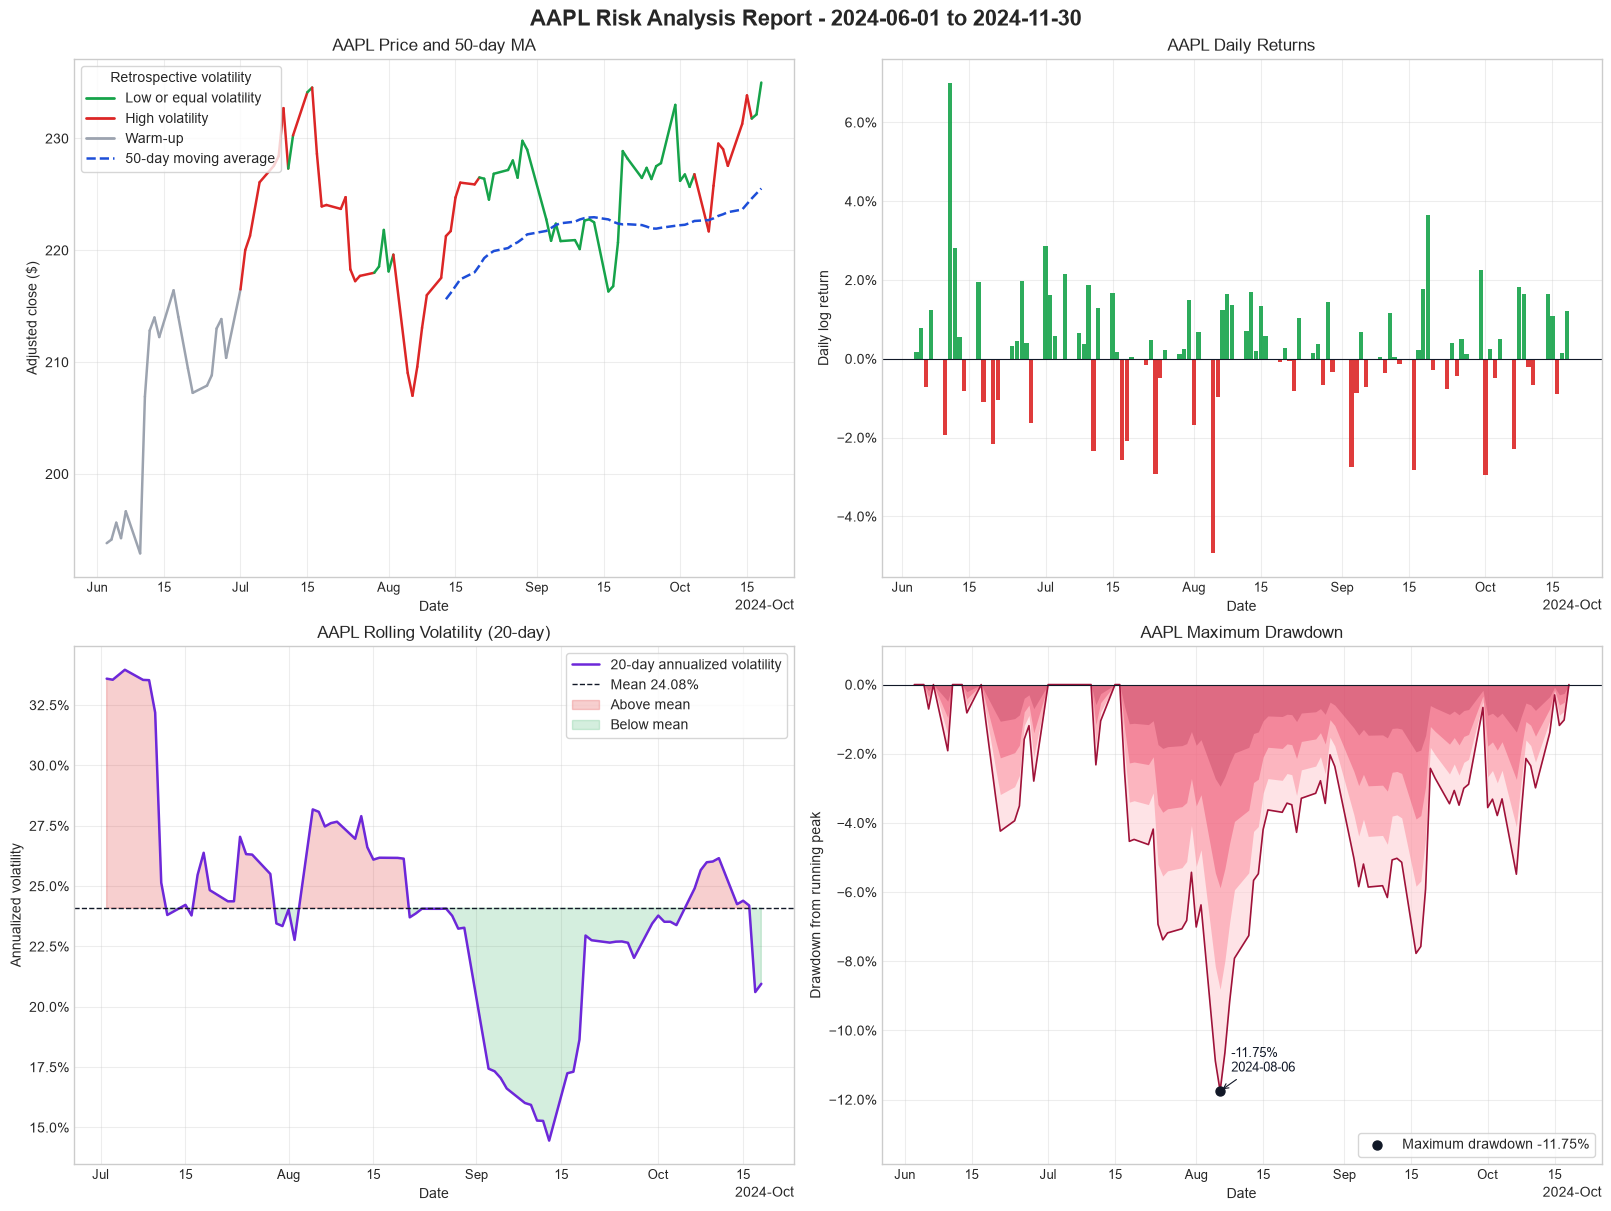

Price colors use the report mean rolling volatility of 24.08%. 20 dates stay gray while the 20-day estimate warms up.
50-day moving average starts on 2024-08-13. The first 49 prices stay blank on that line.


In [9]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

MA_WINDOW = 50
HIGH_VOL = "#dc2626"
LOW_VOL = "#16a34a"
WARMUP = "#9ca3af"
MA_COLOR = "#1d4ed8"
VOL_COLOR = "#6d28d9"
NEUTRAL = "#111827"


def price_segment_color(volatility: float, mean_volatility: float) -> str:
    """Color one price segment from the volatility on its ending date.

    The threshold is the mean rolling volatility of this report. A missing
    estimate is gray. A value above that mean is red. A value equal to or
    below the mean is green.
    """
    if not np.isfinite(volatility) or not np.isfinite(mean_volatility):
        return WARMUP
    if volatility > mean_volatility:
        return HIGH_VOL
    return LOW_VOL


def return_bar_color(value: float) -> str:
    """Green for a positive log return, red for a negative one, gray at zero."""
    if value > 0:
        return LOW_VOL
    if value < 0:
        return HIGH_VOL
    return WARMUP


assert price_segment_color(np.nan, 0.20) == WARMUP
assert price_segment_color(0.30, 0.20) == HIGH_VOL
assert price_segment_color(0.20, 0.20) == LOW_VOL
assert price_segment_color(0.10, 0.20) == LOW_VOL
assert return_bar_color(0.01) == LOW_VOL
assert return_bar_color(-0.01) == HIGH_VOL

if "seaborn-v0_8-whitegrid" in plt.style.available:
    plt.style.use("seaborn-v0_8-whitegrid")

ma_50 = prices["adj_close"].rolling(MA_WINDOW, min_periods=MA_WINDOW).mean()
mean_volatility = float(prices["volatility"].mean())
observed_returns = prices["daily_return"].dropna()
observed_volatility = prices["volatility"].dropna()

assert ma_50.iloc[: MA_WINDOW - 1].isna().all()
if len(prices) >= MA_WINDOW:
    assert ma_50.iloc[MA_WINDOW - 1 :].notna().all()
else:
    assert ma_50.isna().all()
assert prices["volatility"].iloc[:RETURN_WINDOW].isna().all()
assert observed_returns.index.equals(prices.index[1:])

figure, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
ax_price, ax_returns, ax_volatility, ax_drawdown = axes.ravel()

for i in range(1, len(prices)):
    color = price_segment_color(prices["volatility"].iloc[i], mean_volatility)
    ax_price.plot(
        prices.index[i - 1 : i + 1],
        prices["adj_close"].iloc[i - 1 : i + 1],
        color=color,
        linewidth=1.8,
        solid_capstyle="round",
    )

ma_label = "50-day moving average"
if ma_50.notna().any():
    ax_price.plot(
        ma_50.index,
        ma_50,
        color=MA_COLOR,
        linewidth=1.8,
        linestyle="--",
        label=ma_label,
        zorder=4,
    )
else:
    ax_price.text(
        0.02,
        0.04,
        f"50-day moving average needs {MA_WINDOW} prices; this window has {len(prices)}.",
        transform=ax_price.transAxes,
        fontsize=9,
        color=NEUTRAL,
    )

price_handles = [
    Line2D([0], [0], color=LOW_VOL, linewidth=2, label="Low or equal volatility"),
    Line2D([0], [0], color=HIGH_VOL, linewidth=2, label="High volatility"),
    Line2D([0], [0], color=WARMUP, linewidth=2, label="Warm-up"),
]
if ma_50.notna().any():
    price_handles.append(
        Line2D([0], [0], color=MA_COLOR, linewidth=1.8, linestyle="--", label=ma_label)
    )
ax_price.legend(handles=price_handles, loc="upper left", frameon=True, title="Retrospective volatility")
ax_price.set_title(f"{symbol} Price and 50-day MA")
ax_price.set_ylabel("Adjusted close ($)")

ax_returns.bar(
    observed_returns.index,
    observed_returns.to_numpy(),
    width=0.9,
    color=[return_bar_color(value) for value in observed_returns.to_numpy()],
    alpha=0.9,
)
ax_returns.axhline(0, color=NEUTRAL, linewidth=0.8)
ax_returns.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_returns.set_title(f"{symbol} Daily Returns")
ax_returns.set_ylabel("Daily log return")

ax_volatility.plot(
    prices.index,
    prices["volatility"],
    color=VOL_COLOR,
    linewidth=1.8,
    label=f"{RETURN_WINDOW}-day annualized volatility",
)
if np.isfinite(mean_volatility):
    ax_volatility.axhline(
        mean_volatility,
        color=NEUTRAL,
        linewidth=1.0,
        linestyle="--",
        label=f"Mean {format_fraction(mean_volatility)}",
    )
    ax_volatility.fill_between(
        observed_volatility.index,
        observed_volatility,
        mean_volatility,
        where=(observed_volatility > mean_volatility).to_numpy(),
        color=HIGH_VOL,
        alpha=0.22,
        interpolate=True,
        label="Above mean",
    )
    ax_volatility.fill_between(
        observed_volatility.index,
        observed_volatility,
        mean_volatility,
        where=(observed_volatility < mean_volatility).to_numpy(),
        color=LOW_VOL,
        alpha=0.18,
        interpolate=True,
        label="Below mean",
    )
ax_volatility.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_volatility.legend(loc="best", frameon=True)
ax_volatility.set_title(f"{symbol} Rolling Volatility ({RETURN_WINDOW}-day)")
ax_volatility.set_ylabel("Annualized volatility")

for scale, color, alpha in (
    (1.00, "#fecdd3", 0.55),
    (0.75, "#fb7185", 0.40),
    (0.50, "#e11d48", 0.30),
    (0.25, "#9f1239", 0.24),
):
    ax_drawdown.fill_between(
        prices.index,
        prices["drawdown"] * scale,
        0,
        color=color,
        alpha=alpha,
        linewidth=0,
    )
ax_drawdown.plot(prices.index, prices["drawdown"], color="#9f1239", linewidth=1.2)
ax_drawdown.axhline(0, color=NEUTRAL, linewidth=0.8)
ax_drawdown.scatter(
    [worst_drawdown_date],
    [max_drawdown],
    color=NEUTRAL,
    s=42,
    zorder=5,
    label=f"Maximum drawdown {format_fraction(max_drawdown)}",
)
near_right_edge = worst_drawdown_date >= prices.index[int(len(prices) * 0.7)]
ax_drawdown.annotate(
    f"{format_fraction(max_drawdown)}\n{worst_drawdown_date:%Y-%m-%d}",
    xy=(worst_drawdown_date, max_drawdown),
    xytext=(-72, 14) if near_right_edge else (8, 14),
    textcoords="offset points",
    ha="right" if near_right_edge else "left",
    fontsize=9,
    color=NEUTRAL,
    arrowprops={"arrowstyle": "->", "color": NEUTRAL, "lw": 0.8},
)
floor = min(max_drawdown * 1.18, -0.01)
ax_drawdown.set_ylim(floor, abs(floor) * 0.08)
ax_drawdown.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_drawdown.legend(loc="lower right", frameon=True)
ax_drawdown.set_title(f"{symbol} Maximum Drawdown")
ax_drawdown.set_ylabel("Drawdown from running peak")

for ax in axes.flat:
    locator = mdates.AutoDateLocator()
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.35)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.tick_params(axis="x", labelsize=9)

figure.suptitle(
    f"{symbol} Risk Analysis Report - {start} to {end}",
    fontsize=16,
    fontweight="bold",
)
plt.show()

warmup_dates = int(prices["volatility"].isna().sum())
print(
    f"Price colors use the report mean rolling volatility of {format_fraction(mean_volatility)}. "
    f"{warmup_dates} dates stay gray while the {RETURN_WINDOW}-day estimate warms up."
)
if ma_50.notna().any():
    print(
        f"50-day moving average starts on {ma_50.first_valid_index().date()}. "
        f"The first {int(ma_50.isna().sum())} prices stay blank on that line."
    )
else:
    print(
        f"{symbol}: the 50-day moving average is unavailable. "
        f"This window has {len(prices)} prices, and the average needs {MA_WINDOW}. "
        f"The price panel shows the adjusted closes that are available."
    )


## 2.5 Summary statistics

The table below follows section 5 of Lecture 4, module 3 (`Lectures/Lecture 4/3_stock_analysis_template.ipynb`). That section builds `summary_metrics` from the nonmissing log returns and formats a Metric / Value table. The row names here are the homework names. The lecture appends "(log)" to the best-day, worst-day, and average up and down rows; those four rows are still log returns.

Total return is `last_adjusted_close / first_adjusted_close - 1`. On these positive adjusted closes that equals `exp(sum(log_returns)) - 1`, the cumulative return in the lecture.

Annualized return uses the `n` nonmissing log returns: `exp(sum(log_returns) * 252 / n) - 1`. The lecture writes the same rate as `exp(mean_daily_log_return * 252) - 1`. The first price has no return, so it is not part of `n`.

Annualized volatility in this table is the whole-period figure, `std(log_returns) * sqrt(252)`, with the sample standard deviation pandas uses (`ddof=1`). The mean of the 20-day rolling volatility from section 2.3 is a separate number. Part 3 stores that rolling mean as `avg_volatility`. This row leaves it out.

Best day, worst day, and the two averages use log returns. Positive days are the strictly positive returns divided by every nonmissing return, and a zero-return day stays in that denominator. The missing first return is already dropped. An up-day subset with no positive returns, or a down-day subset with no negative returns, displays `N/A`.

`summary_metrics` keeps fractions. The Sharpe ratio keeps the course ratio. Percent signs are display formatting. Positive days print to one decimal place, as in the homework table. The other percentages print to two decimal places, and a return that can be positive carries an explicit sign. Sharpe prints to two decimal places. The figure uses the same green and red as the daily-return bars in section 2.4.

In [10]:
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

SUMMARY_METRICS = [
    "Total Return",
    "Annualized Return",
    "Annualized Volatility",
    "Sharpe Ratio",
    "Maximum Drawdown",
    "Best Day",
    "Worst Day",
    "Positive Days",
    "Average Up Day",
    "Average Down Day",
]
SIGNED_RETURN_METRICS = {
    "Total Return",
    "Annualized Return",
    "Best Day",
    "Worst Day",
    "Average Up Day",
    "Average Down Day",
}
NEUTRAL_SUMMARY_METRICS = {"Annualized Volatility", "Positive Days"}


def calculate_total_return(prices: pd.Series) -> float:
    """Simple return from the first adjusted close to the last.

    The homework definition is last / first - 1. For a path of positive
    prices this equals exp(sum of the daily log returns) - 1, the cumulative
    return in Lecture 4, module 3. Fewer than two prices, or a nonpositive
    endpoint, leaves the return undefined.
    """
    if len(prices) < 2:
        return np.nan
    first = float(prices.iloc[0])
    last = float(prices.iloc[-1])
    if not np.isfinite(first) or not np.isfinite(last) or first <= 0 or last <= 0:
        return np.nan
    return last / first - 1.0


def calculate_annualized_return(log_returns: pd.Series, periods: int = TRADING_DAYS) -> float:
    """Compound the nonmissing daily log returns to an annual rate.

    With n nonmissing returns the rate is exp(sum(log_returns) * periods / n) - 1.
    That is the lecture expression exp(mean_daily_log_return * periods) - 1.
    The missing first return is not included in n. An empty series returns NaN.
    """
    observed = log_returns.dropna()
    n_returns = len(observed)
    if n_returns == 0:
        return np.nan
    return float(np.expm1(observed.sum() * periods / n_returns))


def calculate_period_volatility(log_returns: pd.Series, periods: int = TRADING_DAYS) -> float:
    """Annualize the sample standard deviation of the whole return window.

    The result is std(log_returns) * sqrt(periods). Pandas uses the sample
    standard deviation, ddof=1, on the nonmissing returns. This is one number
    for the window. The mean of the rolling volatility series is a different
    statistic and is not used here. Fewer than two returns leave it undefined.
    """
    observed = log_returns.dropna()
    if len(observed) < 2:
        return np.nan
    sigma = observed.std()
    if not np.isfinite(sigma):
        return np.nan
    return float(sigma * np.sqrt(periods))


def positive_day_share(log_returns: pd.Series) -> float:
    """Share of nonmissing log returns that are strictly positive.

    Zero-return days stay in the denominator and out of the numerator.
    Pass the series after dropping the missing first return; that gap is not
    a zero day. An empty series returns NaN.
    """
    observed = log_returns.dropna()
    if len(observed) == 0:
        return np.nan
    return float(observed.gt(0).mean())


def average_signed_day(log_returns: pd.Series, positive: bool) -> float:
    """Mean log return on up days, or on down days.

    Up days are strictly positive and down days are strictly negative.
    A zero return is in neither average. An empty subset returns NaN,
    which the summary table displays as N/A.
    """
    observed = log_returns.dropna()
    subset = observed.loc[observed > 0] if positive else observed.loc[observed < 0]
    if subset.empty:
        return np.nan
    return float(subset.mean())


def build_summary_metrics(
    prices: pd.Series,
    log_returns: pd.Series,
    drawdown: pd.Series,
) -> pd.Series:
    """Assemble the ten homework summary metrics.

    Best day, worst day, and the up and down averages use log returns.
    Maximum drawdown is the minimum of the per-date drawdown series.
    Sharpe uses the course approximation and the 2% annual risk-free rate.
    Values stay in fractions, except the Sharpe ratio. The series name is
    Value, matching the summary table in Lecture 4, module 3.
    """
    observed = log_returns.dropna()
    values = {
        "Total Return": calculate_total_return(prices),
        "Annualized Return": calculate_annualized_return(observed),
        "Annualized Volatility": calculate_period_volatility(observed),
        "Sharpe Ratio": calculate_sharpe_ratio(observed),
        "Maximum Drawdown": float(drawdown.min()) if len(drawdown) else np.nan,
        "Best Day": float(observed.max()) if len(observed) else np.nan,
        "Worst Day": float(observed.min()) if len(observed) else np.nan,
        "Positive Days": positive_day_share(observed),
        "Average Up Day": average_signed_day(observed, positive=True),
        "Average Down Day": average_signed_day(observed, positive=False),
    }
    return pd.Series(values, name="Value").reindex(SUMMARY_METRICS)


def format_summary_value(metric: str, value: float) -> str:
    """Format one homework summary metric for the display table.

    A missing value, including an empty up-day or down-day average, prints
    as N/A. Sharpe uses two decimal places. Positive days use one decimal
    percent, matching the homework table. Annualized volatility and maximum
    drawdown are unsigned percents at two decimal places. The other return
    rows carry an explicit sign at two decimal places.
    """
    if metric not in SUMMARY_METRICS:
        raise KeyError(f"Unknown summary metric {metric!r}.")
    if pd.isna(value):
        return "N/A"
    if metric == "Sharpe Ratio":
        return f"{value:.2f}"
    if metric == "Positive Days":
        return f"{value:.1%}"
    if metric in SIGNED_RETURN_METRICS:
        return f"{value:+.2%}"
    return f"{value:.2%}"


def format_summary_table(metrics: pd.Series) -> pd.DataFrame:
    """Return the Metric / Value table with display strings only."""
    return pd.DataFrame({
        "Metric": list(metrics.index),
        "Value": [format_summary_value(metric, value) for metric, value in metrics.items()],
    })


def summary_value_color(metric: str, value: float) -> str:
    """Color a summary value the way section 2.4 colors a daily return.

    A gain is green and a loss is red. Annualized volatility and the
    positive-day share describe the window without a sign, so they stay
    neutral. A missing value is the warm-up gray.
    """
    if pd.isna(value) or metric in NEUTRAL_SUMMARY_METRICS:
        return WARMUP if pd.isna(value) else NEUTRAL
    if value > 0:
        return LOW_VOL
    if value < 0:
        return HIGH_VOL
    return NEUTRAL


def draw_summary_table(
    metrics: pd.Series,
    symbol: str,
    start: str,
    end: str,
    n_returns: int,
    rolling_volatility: float,
) -> Figure:
    """Draw the ten-metric homework table.

    The layout is the Metric / Value table from the assignment. Green and
    red match the daily-return panel. The footnote records the total-return
    and annualized-return definitions, and it places the mean rolling
    volatility beside the whole-period volatility used in the table.
    """
    summary_figure, ax = plt.subplots(figsize=(11, 7.6), layout="constrained")
    summary_figure.patch.set_facecolor("white")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.text(
        0.02,
        0.97,
        f"{symbol} Summary Statistics",
        fontsize=18,
        fontweight="bold",
        color=NEUTRAL,
        va="top",
        ha="left",
    )
    ax.text(
        0.02,
        0.905,
        f"{start} to {end}   ·   {n_returns} nonmissing log returns",
        fontsize=11,
        color="#4b5563",
        va="top",
        ha="left",
    )
    ax.plot([0.02, 0.98], [0.855, 0.855], color=NEUTRAL, linewidth=1.15)
    ax.text(0.05, 0.825, "Metric", fontsize=11, fontweight="bold", color="#4b5563", va="center")
    ax.text(0.95, 0.825, "Value", fontsize=11, fontweight="bold", color="#4b5563", va="center", ha="right")

    row_y = 0.765
    row_step = 0.062
    for i, (metric, value) in enumerate(metrics.items()):
        y = row_y - i * row_step
        if i % 2 == 0:
            ax.add_patch(
                plt.Rectangle(
                    (0.02, y - row_step / 2),
                    0.96,
                    row_step,
                    facecolor="#f8fafc",
                    edgecolor="none",
                    zorder=0,
                )
            )
        ax.text(0.05, y, metric, fontsize=12.5, color=NEUTRAL, va="center", ha="left", zorder=1)
        ax.text(
            0.95,
            y,
            format_summary_value(metric, value),
            fontsize=13,
            fontweight="bold",
            color=summary_value_color(metric, value),
            va="center",
            ha="right",
            zorder=1,
        )

    rule_y = row_y - (len(metrics) - 0.5) * row_step
    ax.plot([0.02, 0.98], [rule_y, rule_y], color="#e5e7eb", linewidth=0.9)
    footnote = "\n".join([
        (
            "Total return is the last adjusted close divided by the first, minus one. "
            f"Annualized return compounds {n_returns} nonmissing log returns: exp(sum * 252 / n) - 1."
        ),
        (
            "Annualized volatility is std(log returns) * sqrt(252) for the whole window. "
            f"Mean {RETURN_WINDOW}-day rolling volatility over this report is {format_fraction(rolling_volatility)}."
        ),
    ])
    ax.text(
        0.02,
        rule_y - 0.028,
        footnote,
        fontsize=8.5,
        color="#4b5563",
        va="top",
        ha="left",
        linespacing=1.45,
    )
    ax.set_ylim(0.02, 1.02)
    return summary_figure


### Checks against the homework definitions

The path `100, 110, 110, 99` has three log returns: one up day, one zero day, and one down day. Positive days are `1/3`, because the flat day stays in the denominator. Total return is `99/100 - 1`. Annualized return is `exp(sum(log_returns) * 252 / 3) - 1`, and whole-period volatility is `std(log_returns) * sqrt(252)`.

The path `100, 110, 121` never falls, so it has no down-day average. That cell displays `N/A`. A path of only losses has no up-day average and displays `N/A` the same way. The formatting checks use the sample numbers from the homework table.

In [11]:
check_prices = pd.Series([100.0, 110.0, 110.0, 99.0])
check_returns = calculate_returns(check_prices).dropna()
check_metrics = build_summary_metrics(
    check_prices,
    check_returns,
    calculate_max_drawdown(check_prices),
)
assert np.isclose(check_metrics["Total Return"], 99.0 / 100.0 - 1.0)
assert np.isclose(check_metrics["Total Return"], np.expm1(check_returns.sum()))
assert np.isclose(
    check_metrics["Annualized Return"],
    np.expm1(check_returns.sum() * TRADING_DAYS / len(check_returns)),
)
assert np.isclose(
    check_metrics["Annualized Return"],
    np.expm1(check_returns.mean() * TRADING_DAYS),
)
assert np.isclose(
    check_metrics["Annualized Volatility"],
    check_returns.std() * np.sqrt(TRADING_DAYS),
)
assert np.isclose(check_metrics["Positive Days"], 1.0 / 3.0)
assert np.isclose(check_metrics["Best Day"], np.log(1.1))
assert np.isclose(check_metrics["Worst Day"], np.log(99.0 / 110.0))
assert np.isclose(check_metrics["Average Up Day"], np.log(1.1))
assert np.isclose(check_metrics["Average Down Day"], np.log(99.0 / 110.0))
assert list(check_metrics.index) == SUMMARY_METRICS

gain_prices = pd.Series([100.0, 110.0, 121.0])
gain_metrics = build_summary_metrics(
    gain_prices,
    calculate_returns(gain_prices),
    calculate_max_drawdown(gain_prices),
)
loss_prices = pd.Series([100.0, 90.0, 81.0])
loss_metrics = build_summary_metrics(
    loss_prices,
    calculate_returns(loss_prices),
    calculate_max_drawdown(loss_prices),
)
assert format_summary_value("Average Down Day", gain_metrics["Average Down Day"]) == "N/A"
assert format_summary_value("Average Up Day", loss_metrics["Average Up Day"]) == "N/A"
assert positive_day_share(pd.Series([0.0, 0.0])) == 0.0
assert pd.isna(calculate_annualized_return(pd.Series([np.nan])))
assert pd.isna(calculate_period_volatility(pd.Series([0.01])))

assert format_summary_value("Total Return", 0.2345) == "+23.45%"
assert format_summary_value("Annualized Return", 0.1832) == "+18.32%"
assert format_summary_value("Annualized Volatility", 0.2145) == "21.45%"
assert format_summary_value("Sharpe Ratio", 0.85) == "0.85"
assert format_summary_value("Sharpe Ratio", np.nan) == "N/A"
assert format_summary_value("Maximum Drawdown", -0.1567) == "-15.67%"
assert format_summary_value("Best Day", 0.0523) == "+5.23%"
assert format_summary_value("Worst Day", -0.0489) == "-4.89%"
assert format_summary_value("Positive Days", 0.552) == "55.2%"
assert format_summary_value("Average Up Day", 0.0123) == "+1.23%"
assert format_summary_value("Average Down Day", -0.0115) == "-1.15%"

print("Summary checks passed.")
print("The flat day stays in the denominator: 1 up, 1 zero, 1 down is 33.3% positive.")
display(format_summary_table(check_metrics).style.hide(axis="index"))
print(
    "Average Down Day on an all-up path:",
    format_summary_value("Average Down Day", gain_metrics["Average Down Day"]),
)
print(
    "Average Up Day on an all-down path:",
    format_summary_value("Average Up Day", loss_metrics["Average Up Day"]),
)


Summary checks passed.
The flat day stays in the denominator: 1 up, 1 zero, 1 down is 33.3% positive.


Metric,Value
Total Return,-1.00%
Annualized Return,-57.01%
Annualized Volatility,159.34%
Sharpe Ratio,-0.54
Maximum Drawdown,-10.00%
Best Day,+9.53%
Worst Day,-10.54%
Positive Days,33.3%
Average Up Day,+9.53%
Average Down Day,-10.54%


Average Down Day on an all-up path: N/A
Average Up Day on an all-down path: N/A


### This ticker

The formatted table is the homework layout. The figure repeats those ten rows. `summary_metrics` keeps the fractions, and the Sharpe ratio, for reuse. `stats` holds the fields a later batch can collect. Total return, mean daily log return, maximum drawdown, and the Sharpe ratio are fractions or the course ratio. `avg_volatility` is the mean of the 20-day rolling volatility. Lecture 4 stores total return in percent as `total_return_pct`. The value here stays a fraction, which is the unit Part 3 writes to `portfolio_summary.csv`. The code cell after this ticker's summary saves those names with Scrapbook, the export Lecture 4 uses in module 3. The glued dates are the first and last sessions actually loaded. A history can end before `end_date`. Those missing sessions stay empty.

Metric,Value
Total Return,+21.25%
Annualized Return,+65.84%
Annualized Volatility,25.45%
Sharpe Ratio,1.91
Maximum Drawdown,-11.75%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,62.5%
Average Up Day,+1.09%
Average Down Day,-1.28%


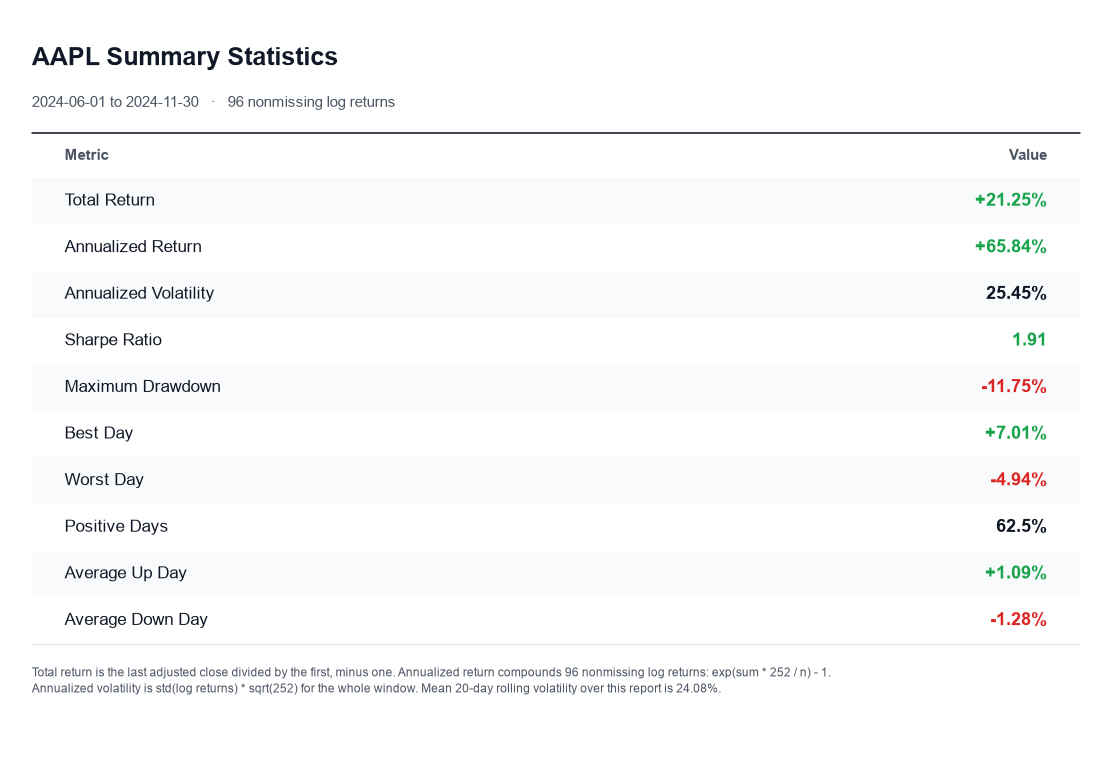

Whole-period annualized volatility is 25.45%. Mean 20-day rolling volatility is 24.08%. The summary table uses the whole-period number.
AAPL: total return +21.25% from 193.81 to 235.00. Sharpe ratio 1.91.


In [12]:
summary_metrics = build_summary_metrics(
    prices["adj_close"],
    prices["daily_return"],
    prices["drawdown"],
)
n_returns = len(log_returns)
mean_rolling_volatility = float(prices["volatility"].mean())
expected_up = log_returns.loc[log_returns > 0].mean()
expected_down = log_returns.loc[log_returns < 0].mean()

assert n_returns == int(prices["daily_return"].notna().sum())
assert np.isclose(
    summary_metrics["Total Return"],
    prices["adj_close"].iloc[-1] / prices["adj_close"].iloc[0] - 1,
)
assert np.isclose(summary_metrics["Total Return"], np.expm1(log_returns.sum()))
assert np.isclose(
    summary_metrics["Annualized Return"],
    np.expm1(log_returns.sum() * TRADING_DAYS / n_returns),
)
assert np.isclose(
    summary_metrics["Annualized Volatility"],
    log_returns.std() * np.sqrt(TRADING_DAYS),
)
assert np.isclose(summary_metrics["Maximum Drawdown"], max_drawdown)
assert np.isclose(summary_metrics["Best Day"], log_returns.max())
assert np.isclose(summary_metrics["Worst Day"], log_returns.min())
assert np.isclose(summary_metrics["Positive Days"], log_returns.gt(0).sum() / n_returns)
if pd.isna(sharpe_ratio):
    assert pd.isna(summary_metrics["Sharpe Ratio"])
else:
    assert np.isclose(summary_metrics["Sharpe Ratio"], sharpe_ratio)
assert pd.isna(summary_metrics["Average Up Day"]) and pd.isna(expected_up) or np.isclose(
    summary_metrics["Average Up Day"], expected_up
)
assert pd.isna(summary_metrics["Average Down Day"]) and pd.isna(expected_down) or np.isclose(
    summary_metrics["Average Down Day"], expected_down
)

sharpe_value = summary_metrics["Sharpe Ratio"]
stats = {
    "ticker": symbol,
    "start_date": start,
    "end_date": end,
    "trading_days": int(len(prices)),
    "n_returns": n_returns,
    "total_return": float(summary_metrics["Total Return"]),
    "annualized_return": float(summary_metrics["Annualized Return"]),
    "annualized_volatility": float(summary_metrics["Annualized Volatility"]),
    "avg_daily_return": float(log_returns.mean()),
    "avg_volatility": mean_rolling_volatility,
    "max_drawdown": float(summary_metrics["Maximum Drawdown"]),
    "sharpe_ratio": float(sharpe_value) if pd.notna(sharpe_value) else np.nan,
}

display_summary = format_summary_table(summary_metrics)
display(display_summary.style.hide(axis="index"))

summary_figure = draw_summary_table(
    summary_metrics,
    symbol=symbol,
    start=start,
    end=end,
    n_returns=n_returns,
    rolling_volatility=mean_rolling_volatility,
)
plt.show()

print(
    f"Whole-period annualized volatility is "
    f"{format_summary_value('Annualized Volatility', summary_metrics['Annualized Volatility'])}. "
    f"Mean {RETURN_WINDOW}-day rolling volatility is {format_fraction(mean_rolling_volatility)}. "
    "The summary table uses the whole-period number."
)
print(
    f"{symbol}: total return {format_summary_value('Total Return', summary_metrics['Total Return'])} "
    f"from {prices['adj_close'].iloc[0]:.2f} to {prices['adj_close'].iloc[-1]:.2f}. "
    f"Sharpe ratio {format_summary_value('Sharpe Ratio', summary_metrics['Sharpe Ratio'])}."
)


In [13]:
import math

import scrapbook as sb


def glue_number(name: str, value: float) -> None:
    """Save a finite metric under `name`.

    Scrapbook stores JSON. An undefined Sharpe ratio, or any other non-finite
    metric, is saved as None. The batch runner turns that None back into a
    missing value and leaves it out of the Sharpe ranking.
    """
    number = float(value)
    sb.glue(name, number if math.isfinite(number) else None)


sb.glue("ticker", stats["ticker"])
sb.glue("start_date", stats["start_date"])
sb.glue("end_date", stats["end_date"])
sb.glue("first_observation", str(first_obs.date()))
sb.glue("last_observation", str(last_obs.date()))
sb.glue("trading_days", int(stats["trading_days"]))
glue_number("avg_daily_return", stats["avg_daily_return"])
glue_number("avg_volatility", stats["avg_volatility"])
glue_number("max_drawdown", stats["max_drawdown"])
glue_number("sharpe_ratio", stats["sharpe_ratio"])
glue_number("total_return", stats["total_return"])
print(
    f"Saved named outputs for {symbol}: "
    f"{first_obs.date()} to {last_obs.date()} "
    f"({stats['trading_days']} trading days inside the requested window {start} to {end})."
)


Saved named outputs for AAPL: 2024-06-03 to 2024-10-18 (97 trading days inside the requested window 2024-06-01 to 2024-11-30).
